<a href="https://colab.research.google.com/github/nasywa-raichanah/10/blob/main/0_1_ringkasan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import random
import os
import time
import math
import matplotlib.pyplot as plt
import numpy as np
import glob
import re
from google.colab import drive
from IPython.display import display

In [ ]:
drive.mount('/content/drive')
dataset_path = "/content/drive/MyDrive/Tugas Akhir/Dataset/"
revisi_path = "/content/drive/MyDrive/Tugas Akhir/0.1/"

Mounted at /content/drive


In [ ]:
kelas_df       = pd.read_csv(dataset_path + "kelas.csv")
mapel_df       = pd.read_csv(dataset_path + "mapel.csv")
guru_df        = pd.read_csv(dataset_path + "guru.csv")
timeslot_df    = pd.read_csv(dataset_path + "timeslot.csv")
guru_mapel_df  = pd.read_csv(dataset_path + "guru_mapel.csv")
mapel_kelas_df = pd.read_csv(dataset_path + "mapel_kelas.csv")

In [ ]:
MAP_GURU = dict(zip(guru_df['id_guru'], guru_df['nama_guru']))
MAP_KELAS = dict(zip(kelas_df['id_kelas'], kelas_df['nama_kelas']))
MAP_MAPEL = dict(zip(mapel_df['id_mapel'], mapel_df['nama_mapel']))
SLOT_LIST = timeslot_df.to_dict('records')
TOTAL_SLOTS = len(SLOT_LIST)
ALL_CLASSES = kelas_df['id_kelas'].unique().tolist()

In [ ]:
GENES = []
for _, row in mapel_kelas_df.iterrows():
    id_mapel = row['id_mapel']
    id_kelas = row['id_kelas']
    total_jam = row['jam_perminggu']

    kandidat_guru = guru_mapel_df[
        (guru_mapel_df['id_mapel'] == id_mapel) &
        (guru_mapel_df['id_kelas'] == id_kelas)
    ]['id_guru'].tolist()

    if len(kandidat_guru) == 0: continue

    sisa = total_jam
    while sisa > 0:
        durasi = 2 if sisa >= 2 else 1
        GENES.append({
            'id_mapel': id_mapel,
            'id_kelas': id_kelas,
            'id_guru': random.choice(kandidat_guru),
            'durasi': durasi
        })
        sisa -= durasi

In [ ]:
slot_per_hari = {}
for idx, slot in enumerate(SLOT_LIST):
    hari = slot['hari']
    if hari not in slot_per_hari: slot_per_hari[hari] = []
    slot_per_hari[hari].append(idx)

VALID_START = {}
max_durasi = max(g['durasi'] for g in GENES) if GENES else 2
for d in range(1, max_durasi + 1):
    valid_indices = []
    for hari, indices in slot_per_hari.items():
        limit = len(indices) - d
        if limit >= 0:
            valid_indices.extend(indices[:limit + 1])
    VALID_START[d] = valid_indices

In [ ]:
def create_individual():
    jadwal = []
    for gene in GENES:
        jadwal.append(random.choice(VALID_START[gene['durasi']]))
    return jadwal

In [ ]:
def get_total_penalty(jadwal):
    penalty = 0
    occupied_teacher = set()
    occupied_class = {}
    subj_on_day = set()

    for i, start_index in enumerate(jadwal):
        gene = GENES[i]
        durasi = gene['durasi']
        mapel_id = gene['id_mapel']
        kelas_id = gene['id_kelas']
        guru_id = gene['id_guru']

        if start_index + durasi > TOTAL_SLOTS: penalty += 10

        hari_sekarang = SLOT_LIST[start_index]['hari']
        subj_day_key = (kelas_id, mapel_id, hari_sekarang)
        if subj_day_key in subj_on_day: penalty += 4
        else: subj_on_day.add(subj_day_key)

        for offset in range(durasi):
            current_slot = start_index + offset
            if (current_slot, guru_id) in occupied_teacher: penalty += 10
            else: occupied_teacher.add((current_slot, guru_id))

            key_kelas = (current_slot, kelas_id)
            if key_kelas in occupied_class:
                if mapel_id != occupied_class[key_kelas]: penalty += 10
            else: occupied_class[key_kelas] = mapel_id

        if mapel_id == 'PJOK':
            try:
                current_jam = SLOT_LIST[start_index]["jam_ke"]
                if current_jam > 6: penalty +=1
                for offset in range(durasi-1):
                    nxt = SLOT_LIST[start_index + offset + 1]['jam_ke']
                    if (current_jam+offset == 4 and nxt == 5) or (current_jam+offset == 6 and nxt == 7):
                        penalty += 1
            except: pass
    return penalty

In [ ]:
def tournament_selection_opt(pop_evaluated, k=2):
    contenders = random.sample(pop_evaluated, k)
    return max(contenders, key=lambda x: x[2])[0]

def roulette_wheel_selection_opt(pop_evaluated):
    fitness_values = [x[2] for x in pop_evaluated]
    return random.choices(pop_evaluated, weights=fitness_values, k=1)[0][0]

def rank_selection_opt(pop_evaluated):
    N = len(pop_evaluated)
    weights = list(range(N, 0, -1))
    return random.choices(pop_evaluated, weights=weights, k=1)[0][0]

def sus_selection_opt(pop_evaluated, num_parents=1):
    total_fitness = sum([x[2] for x in pop_evaluated])
    distance = total_fitness / num_parents
    start = random.uniform(0, distance)
    pointers = [start + i * distance for i in range(num_parents)]
    selected_schedules = []
    idx = 0
    cumulative_fitness = pop_evaluated[0][2]
    for pointer in pointers:
        while cumulative_fitness < pointer and idx < len(pop_evaluated) - 1:
            idx += 1
            cumulative_fitness += pop_evaluated[idx][2]
        selected_schedules.append(pop_evaluated[idx][0])
    return selected_schedules[0]

def boltzmann_selection_opt(pop_evaluated, temperature=100.0):
    max_fitness = max(x[2] for x in pop_evaluated)
    weights = [math.exp((x[2] - max_fitness) / temperature) for x in pop_evaluated]
    return random.choices(pop_evaluated, weights=weights, k=1)[0][0]

In [ ]:
def one_point_crossover(p1, p2, PC):
    if random.random() < PC:
        titik = random.randint(1, len(p1) - 1)
        return p1[:titik] + p2[titik:], p2[:titik] + p1[titik:]
    return p1[:], p2[:]

def two_point_crossover(p1, p2, PC):
    if random.random() < PC:
        t1, t2 = sorted(random.sample(range(1, len(p1) - 1), 2))
        return p1[:t1] + p2[t1:t2] + p1[t2:], p2[:t1] + p1[t1:t2] + p2[t2:]
    return p1[:], p2[:]

def uniform_crossover(p1, p2, PC):
    if random.random() < PC:
        c1, c2 = [], []
        for i in range(len(p1)):
            if random.random() < 0.5:
                c1.append(p2[i]); c2.append(p1[i])
            else:
                c1.append(p1[i]); c2.append(p2[i])
        return c1, c2
    return p1[:], p2[:]

In [ ]:
def get_conflicted_indices(jadwal):
    bad_indices = set()
    occupied_teacher = {}
    occupied_class = {}
    subj_on_day = {}
    for i, start_index in enumerate(jadwal):
        gene = GENES[i]
        durasi = gene['durasi']
        mapel_id = gene['id_mapel']
        kelas_id = gene['id_kelas']
        guru_id = gene['id_guru']

        if start_index + durasi > TOTAL_SLOTS:
            bad_indices.add(i); continue

        hari_sekarang = SLOT_LIST[start_index]['hari']
        subj_key = (kelas_id, mapel_id, hari_sekarang)
        if subj_key in subj_on_day:
            bad_indices.add(i)
            bad_indices.add(subj_on_day[subj_key])
        else: subj_on_day[subj_key] = i

        for offset in range(durasi):
            current_slot = start_index + offset
            key_guru = (current_slot, guru_id)
            if key_guru in occupied_teacher:
                bad_indices.add(i)
                bad_indices.add(occupied_teacher[key_guru])
            else: occupied_teacher[key_guru] = i

            key_kelas = (current_slot, kelas_id)
            if key_kelas in occupied_class:
                if mapel_id != occupied_class[key_kelas]: bad_indices.add(i)
            else: occupied_class[key_kelas] = mapel_id
    return list(bad_indices)

In [ ]:
def mutate(jadwal, PM):
    jadwal_baru = list(jadwal)
    bad_indices = get_conflicted_indices(jadwal_baru)
    if bad_indices:
        k = max(1, int(0.5 * len(bad_indices)))
        targets = random.sample(bad_indices, k)
    else:
        targets = [random.randint(0, len(jadwal_baru) - 1)]

    for idx in targets:
        gene = GENES[idx]
        forbidden_days = set([SLOT_LIST[s]['hari'] for i, s in enumerate(jadwal_baru) if i != idx])
        all_options = VALID_START[gene['durasi']]
        safe_options = [s for s in all_options if SLOT_LIST[s]['hari'] not in forbidden_days]
        jadwal_baru[idx] = random.choice(safe_options) if safe_options else random.choice(all_options)
    return jadwal_baru

In [ ]:
def run_ga_once(run_number, f_seleksi, f_crossover, pop_size, gens, pm, pc):
    population = [create_individual() for _ in range(pop_size)]
    best_global_penalty = float('inf')
    best_global = None
    stagnation_counter = 0

    for gen in range(1, gens + 1):
        pop_evaluated = []
        for ind in population:
            p = get_total_penalty(ind)
            f = 1.0 / (1.0 + p)
            pop_evaluated.append((ind, p, f))

        pop_evaluated.sort(key=lambda x: x[2], reverse=True)
        best_gen_ind = pop_evaluated[0][0]
        current_penalty = pop_evaluated[0][1]

        if current_penalty < best_global_penalty:
            best_global_penalty = current_penalty
            best_global = best_gen_ind.copy()
            stagnation_counter = 0
        else:
            stagnation_counter += 1

        if current_penalty == 0: break

        if stagnation_counter > 300:
            population = [create_individual() for _ in range(pop_size - 1)]
            population.append(best_global.copy())
            stagnation_counter = 0
            continue

        new_population = [x[0].copy() for x in pop_evaluated[:5]]
        while len(new_population) < pop_size:
            p1 = f_seleksi(pop_evaluated)
            p2 = f_seleksi(pop_evaluated)
            c1, c2 = f_crossover(p1, p2, pc)
            if random.random() < pm: c1 = mutate(c1, pm)
            new_population.append(c1)
            if len(new_population) < pop_size:
                if random.random() < pm: c2 = mutate(c2, pm)
                new_population.append(c2)
        population = new_population

    return {'best_chromosome': best_global, 'best_penalty': best_global_penalty}

In [ ]:
POPULATION_SIZE = 100
GENERATIONS = 2000
PM = 0.06
PC = 0.85

In [ ]:
list_skenario = {
    1: {"nama": "Skenario 1 (Roulette + 1-Point)", "sel": roulette_wheel_selection_opt, "cross": one_point_crossover},
    2: {"nama": "Skenario 2 (Roulette + 2-Point)", "sel": roulette_wheel_selection_opt, "cross": two_point_crossover},
    3: {"nama": "Skenario 3 (Roulette + Uniform)", "sel": roulette_wheel_selection_opt, "cross": uniform_crossover},
    4: {"nama": "Skenario 4 (Tournament + 1-Point)", "sel": lambda p: tournament_selection_opt(p, k=2), "cross": one_point_crossover},
    5: {"nama": "Skenario 5 (Tournament + 2-Point)", "sel": lambda p: tournament_selection_opt(p, k=2), "cross": two_point_crossover},
    6: {"nama": "Skenario 6 (Tournament + Uniform)", "sel": lambda p: tournament_selection_opt(p, k=2), "cross": uniform_crossover},
    7: {"nama": "Skenario 7 (Rank + 1-Point)", "sel": rank_selection_opt, "cross": one_point_crossover},
    8: {"nama": "Skenario 8 (Rank + 2-Point)", "sel": rank_selection_opt, "cross": two_point_crossover},
    9: {"nama": "Skenario 9 (Rank + Uniform)", "sel": rank_selection_opt, "cross": uniform_crossover},
    10: {"nama": "Skenario 10 (SUS + 1-Point)", "sel": sus_selection_opt, "cross": one_point_crossover},
    11: {"nama": "Skenario 11 (SUS + 2-Point)", "sel": sus_selection_opt, "cross": two_point_crossover},
    12: {"nama": "Skenario 12 (SUS + Uniform)", "sel": sus_selection_opt, "cross": uniform_crossover},
    13: {"nama": "Skenario 13 (Boltzmann + 1-Point)", "sel": lambda p: boltzmann_selection_opt(p, temperature=100.0), "cross": one_point_crossover},
    14: {"nama": "Skenario 14 (Boltzmann + 2-Point)", "sel": lambda p: boltzmann_selection_opt(p, temperature=100.0), "cross": two_point_crossover},
    15: {"nama": "Skenario 15 (Boltzmann + Uniform)", "sel": lambda p: boltzmann_selection_opt(p, temperature=100.0), "cross": uniform_crossover}
}


Berhasil memuat 15 data skenario. Memproses grafik...


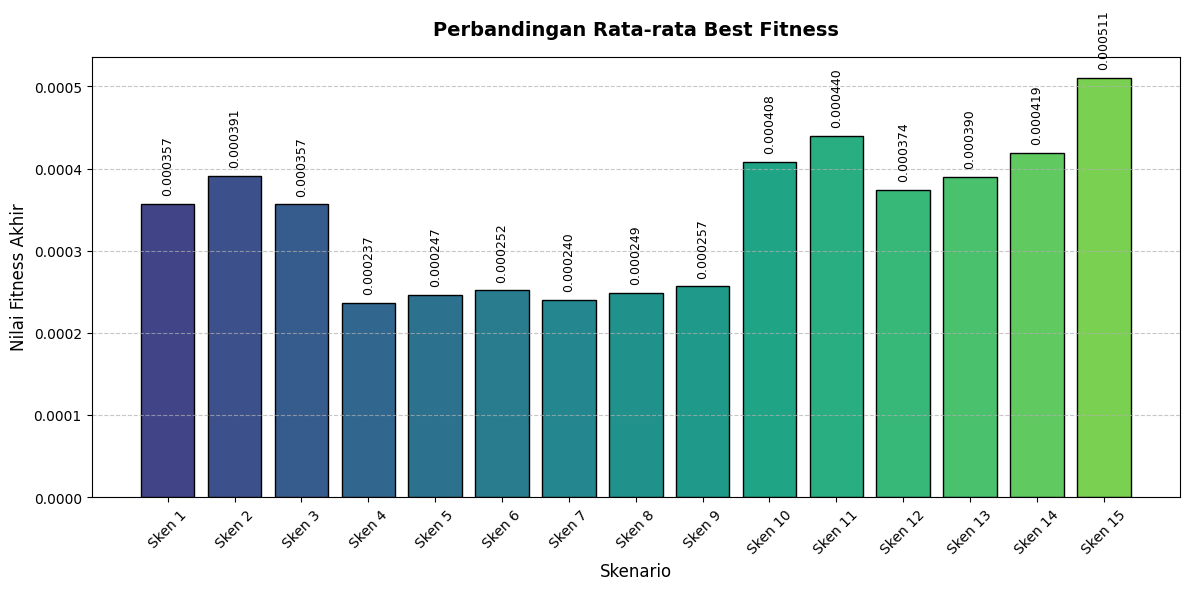

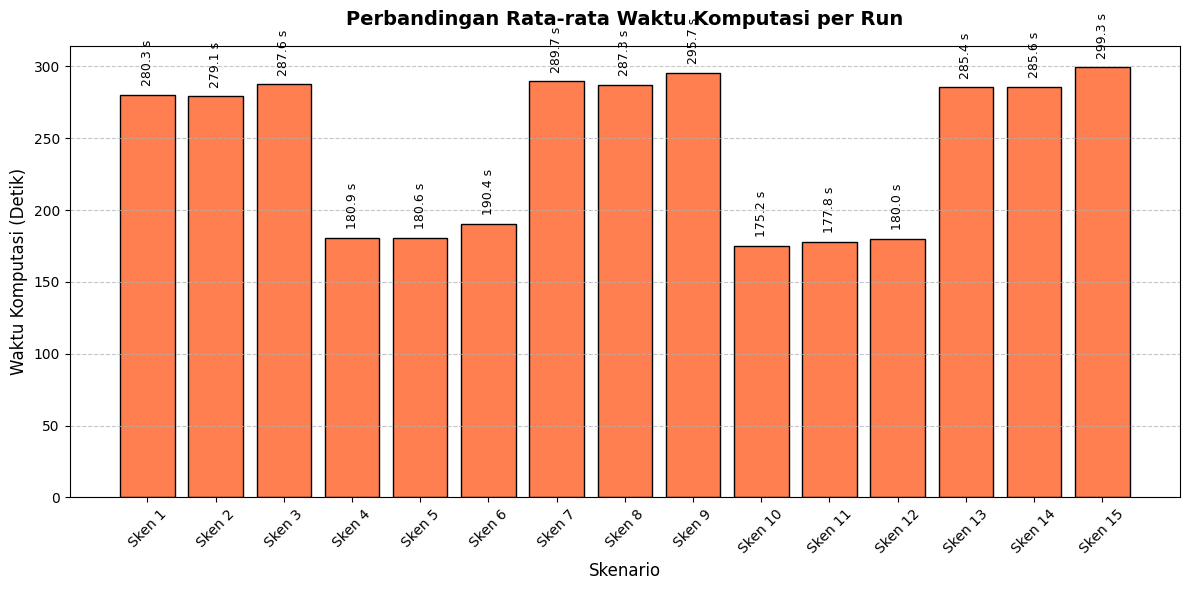

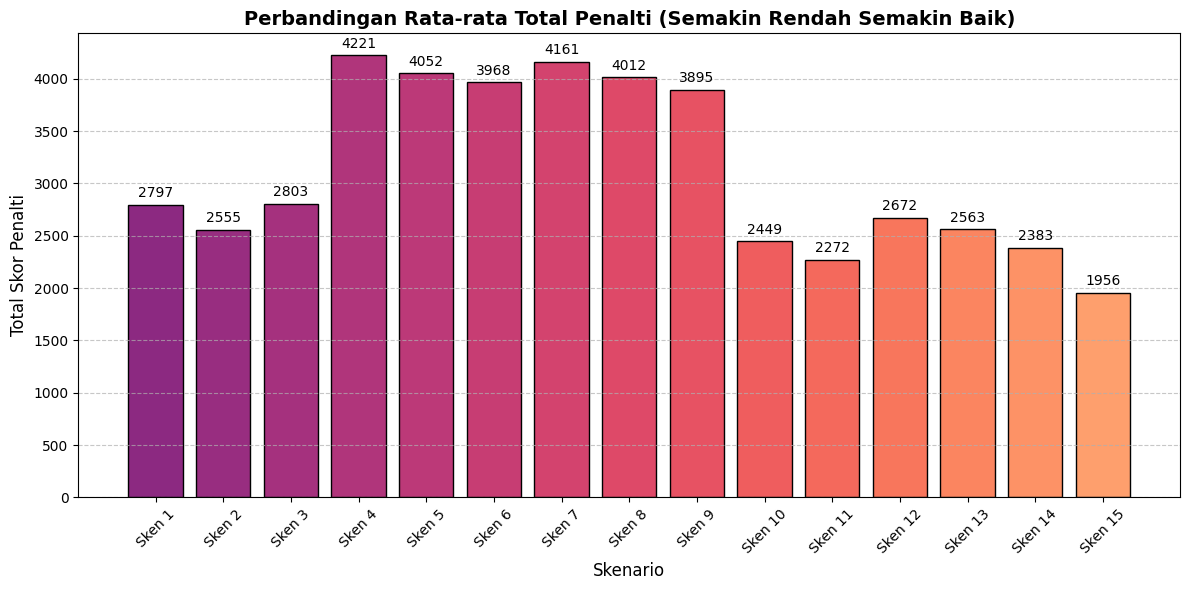


🥇 SKENARIO TERBAIK: Skenario 15
Rata-rata Penalti Terendah: 1956.4030
Mengeksekusi ulang Skenario Terbaik (1x Run) untuk mendapatkan jadwal...
Selesai! Penalti jadwal yang dihasilkan: 5214

TABEL JADWAL PELAJARAN (Hasil Skenario 15)



💾 File Excel jadwal (Format Matriks) berhasil disimpan di: /content/drive/MyDrive/Tugas Akhir/0.1/Jadwal_Terbaik_Skenario_15.xlsx


In [ ]:
def ekstrak_angka_untuk_sorting(filepath):
    nama = os.path.basename(filepath)
    cari = re.search(r'\d+', nama)
    return int(cari.group()) if cari else 999

pencarian_file = os.path.join(revisi_path, "Hasil_*.csv")
file_tersedia = sorted(glob.glob(pencarian_file), key=ekstrak_angka_untuk_sorting)

rata_rata_fitness = []
rata_rata_waktu = []
skenario_berhasil = []
rata_rata_penalti = []

for path_lengkap in file_tersedia:
    nama_file = os.path.basename(path_lengkap)
    cari_angka = re.search(r'\d+', nama_file)
    label_skenario = cari_angka.group() if cari_angka else "?"

    df = pd.read_csv(path_lengkap)
    baris_rata = df.iloc[-1]

    fit_val = baris_rata['Best Fitness']
    rata_rata_fitness.append(fit_val)
    rata_rata_waktu.append(baris_rata['Waktu (Detik)'])
    skenario_berhasil.append(f"Sken {label_skenario}")

    penalti_val = (1 / fit_val) - 1
    rata_rata_penalti.append(penalti_val)

if not skenario_berhasil:
    print(f"\nBelum ada file data skenario di folder: {revisi_path}")
else:
    print(f"\nBerhasil memuat {len(skenario_berhasil)} data skenario. Memproses grafik...")

    # -- Grafik Fitness --
    colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(skenario_berhasil)))
    plt.figure(figsize=(12, 6))
    bars1 = plt.bar(skenario_berhasil, rata_rata_fitness, color=colors, edgecolor='black')
    plt.title("Perbandingan Rata-rata Best Fitness", fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("Skenario", fontsize=12)
    plt.ylabel("Nilai Fitness Akhir", fontsize=12)
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    for bar in bars1:
        yval = bar.get_height()
        teks_nilai = f"{yval:.6f}" if yval < 0.01 else f"{yval:.4f}"
        plt.text(bar.get_x() + bar.get_width()/2, yval + (max(rata_rata_fitness)*0.02), teks_nilai, ha='center', va='bottom', fontsize=9, rotation=90)
    plt.tight_layout()
    plt.show()

    # -- Grafik Waktu --
    plt.figure(figsize=(12, 6))
    bars2 = plt.bar(skenario_berhasil, rata_rata_waktu, color='coral', edgecolor='black')
    plt.title("Perbandingan Rata-rata Waktu Komputasi per Run", fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("Skenario", fontsize=12)
    plt.ylabel("Waktu Komputasi (Detik)", fontsize=12)
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    for bar in bars2:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval + (max(rata_rata_waktu)*0.02), f"{yval:.1f} s", ha='center', va='bottom', fontsize=9, rotation=90)
    plt.tight_layout()
    plt.show()

    # -- Grafik Penalti --
    colors_penalti = plt.cm.magma(np.linspace(0.4, 0.8, len(skenario_berhasil)))
    plt.figure(figsize=(12, 6))
    bars3 = plt.bar(skenario_berhasil, rata_rata_penalti, color=colors_penalti, edgecolor='black')
    plt.title("Perbandingan Rata-rata Total Penalti (Semakin Rendah Semakin Baik)", fontsize=14, fontweight='bold')
    plt.xlabel("Skenario", fontsize=12)
    plt.ylabel("Total Skor Penalti", fontsize=12)
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    for bar in bars3:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval + (max(rata_rata_penalti)*0.01), f"{int(yval)}", ha='center', va='bottom', fontsize=10)
    plt.tight_layout()
    plt.show()

# EKSEKUSI SKENARIO TERBAIK & CETAK JADWAL
if skenario_berhasil:
    skenario_terbaik_idx = np.argmin(rata_rata_penalti)
    skenario_terbaik_label = skenario_berhasil[skenario_terbaik_idx]
    skenario_terbaik_nomor = int(re.search(r'\d+', skenario_terbaik_label).group())

    print("\n" + "="*50)
    print(f"🥇 SKENARIO TERBAIK: Skenario {skenario_terbaik_nomor}")
    print(f"Rata-rata Penalti Terendah: {rata_rata_penalti[skenario_terbaik_idx]:.4f}")
    print("Mengeksekusi ulang Skenario Terbaik (1x Run) untuk mendapatkan jadwal...")
    print("="*50)

    konfigurasi_terbaik = list_skenario[skenario_terbaik_nomor]
    hasil_terbaik = run_ga_once(
        run_number=1,
        f_seleksi=konfigurasi_terbaik['sel'],
        f_crossover=konfigurasi_terbaik['cross'],
        pop_size=POPULATION_SIZE,
        gens=GENERATIONS,
        pm=PM,
        pc=PC
    )

    best_chromosome = hasil_terbaik['best_chromosome']
    print(f"Selesai! Penalti jadwal yang dihasilkan: {hasil_terbaik['best_penalty']}")

    def decode_jadwal_matrix(chromosome):
        jadwal_list = []
        for i, start_index in enumerate(chromosome):
            gene = GENES[i]
            slot = SLOT_LIST[start_index]

            hari = slot['hari']
            jam_awal = slot['jam_ke']
            durasi = gene['durasi']

            kelas_full = str(MAP_KELAS[gene['id_kelas']])

            parts = kelas_full.replace("Kelas ", "").split(' ', 1)
            tingkat = f"Kelas {parts[0]}"
            sub_kelas = parts[1] if len(parts) > 1 else ""

            mapel_kode = str(gene['id_mapel'])
            guru_kode = str(gene['id_guru'])

            isi_sel = f"{mapel_kode}\n-\n{guru_kode}"

            for d in range(durasi):
                jam_ke = jam_awal + d
                jadwal_list.append({
                    'Hari': hari,
                    'Jam_ke': jam_ke,
                    'Tingkat': tingkat,
                    'Sub_Kelas': sub_kelas,
                    'Mapel_Guru': isi_sel
                })

        df = pd.DataFrame(jadwal_list)

        sort_hari = {'Senin': 1, 'Selasa': 2, 'Rabu': 3, 'Kamis': 4, 'Jumat': 5, 'Sabtu': 6, 'Minggu': 7}
        df['Hari_Num'] = df['Hari'].map(sort_hari).fillna(99)

        df_pivot = df.pivot_table(
            index=['Hari_Num', 'Hari', 'Jam_ke'],
            columns=['Tingkat', 'Sub_Kelas'],
            values='Mapel_Guru',
            aggfunc=lambda x: ' / '.join(x.dropna())
        )

        df_pivot = df_pivot.sort_index(axis=0)
        df_pivot = df_pivot.sort_index(axis=1)

        df_pivot = df_pivot.reset_index(level='Hari_Num', drop=True)

        return df_pivot

    df_jadwal_terbaik = decode_jadwal_matrix(best_chromosome)

    print("\n=======================================================")
    print(f"TABEL JADWAL PELAJARAN (Hasil Skenario {skenario_terbaik_nomor})")
    print("=======================================================")

    display(df_jadwal_terbaik.style.set_properties(**{
        'white-space': 'pre-wrap',
        'text-align': 'center',
        'vertical-align': 'middle'
    }))

    path_simpan_jadwal = os.path.join(revisi_path, f"Jadwal_Terbaik_Skenario_{skenario_terbaik_nomor}.xlsx")

    df_jadwal_terbaik.to_excel(path_simpan_jadwal)
    print(f"\n💾 File Excel jadwal (Format Matriks) berhasil disimpan di: {path_simpan_jadwal}")